# Analyze AQS stress soft corr

We have AQS simulation (with and without preshear) at a number of oscillatory
shears

We need to compute softness intercycle and get the local virial intercycle

## Setup

In [1]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import cm, colors

import glob
import gc
import warnings
import copy
import pathlib
import pickle

import os
import shutil

from scipy import stats
import signac
import freud
import gsd.hoomd
import hoomd
import schmeud
import schmeud._schmeud as schmeud_rs
from schmeud._schmeud import statics
from schmeud._schmeud import locality
from schmeud import ml
from tqdm import tqdm

from dataclasses import dataclass
from collections import defaultdict

from numba import njit

In [2]:
from monk import nb, prep as prep_mod, pair, render, utils, workflow, grid

parent = pathlib.Path(os.getcwd()).parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())
parent, config

(PosixPath('/home/ian/Projects/work/monk/workflows/2d-osc-shear/config.yaml'),
 {'root': '/media/ian/Data2/monk/2d-osc-shear',
  'origin': '/media/ian/Data2/monk/2d-esl'})

In [3]:
project: signac.Project = signac.get_project(root=config['root'])
project.doc

{'avail_seed': 18, 'dt': 0.005, 'step_unit': 200, 'equil_time': 100, 'min_periods': 20, 'dumps': 40, 'period_times': [30.0, 100.0, 300.0, 1000.0], 'max_shears': [0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.04, 0.06, 0.07], '_status': {}}

## Generate data

In [4]:
@dataclass(frozen=True, eq=True)
class Statepoint:
    max_shear: float
    period: float
    temp: float
    prep: str

## Analyze data

In [5]:
output = defaultdict(list)

trajs = {}

for job in project:
    print(job)
    prep = job.sp["prep"]
    # if prep == "HTL":
    #     continue
    
    experiments = sorted(glob.glob(job.fn("aqs_experiments_preshear/*/*/traj_period-*.gsd")))
    if len(experiments) == 0:
        continue
    for exper in experiments:
        max_shear = utils.extract_between(exper, "max-shear-", "/")
        period = utils.extract_between(exper, "period-", "_preshear")
        temp = utils.extract_between(exper, "temp-", "/")
        df_path = exper.replace("traj_period", "soft-stress_period").replace(".gsd", ".parquet")
        sp = Statepoint(max_shear=float(max_shear), period=float(period), temp=float(temp), prep=prep)

        if sp in output:
            continue

        if sp.max_shear != 0.05:
            continue
        print("we good!")
        if job.isfile(df_path):
            traj = gsd.hoomd.open(name=exper, mode='rb')
            dataset = pl.read_parquet(job.fn(df_path))
            output[sp].append((dataset, traj))
    # break

634e14bc75836df75158fb15f379d8bb
we good!
7ec2f6aca035e69077eab24383a21cb6
we good!
cfa1e4c0007fd65d020f809715a6f0b4
ecce68c50e28a33684826f28780bf6e9
1d0fe2ba44a6f635f5504dcbcee0ebc9
1083a2a09eec2c6cf215ebc7a9706cac
09d3dccc56f1fa9330b57901cd232ab7
6976a7c10ada4159010403f8027f3ea5
9158e73b2e4c9fd1a565e1e5d1bc3af5
c6d7afd0de62bfa16d05da47815227eb
bf92a185d043ce3ef666e05e427c7e76
a8f2c249ed85533b56b0729b7ab96d18


In [6]:
prep

'ESL'

In [7]:
for key, val in output.items():
    print(key)
    # if key.max_shear == 0.03:
    dataset = val[0][0]
    sigma_xx = np.vstack(dataset["sigma_xx"].to_numpy())
    sigma_yy = np.vstack(dataset["sigma_yy"].to_numpy())
    sigma_xy = np.vstack(dataset["sigma_xy"].to_numpy())
    sigma_dev = np.sqrt((sigma_xx - sigma_yy)**2 + sigma_xy**2)
    dataset = dataset.with_columns([pl.Series("sigma_dev", sigma_dev)])
    if key.prep == "HTL":
        dataset_htl = dataset
        traj_htl = val[0][1]
    else:
        dataset_gq = dataset
        traj_gq = val[0][1]

Statepoint(max_shear=0.05, period=0.001, temp=0.0, prep='HTL')
Statepoint(max_shear=0.05, period=0.001, temp=0.0, prep='ESL')


In [8]:
dataset_htl.shape

(840, 8)

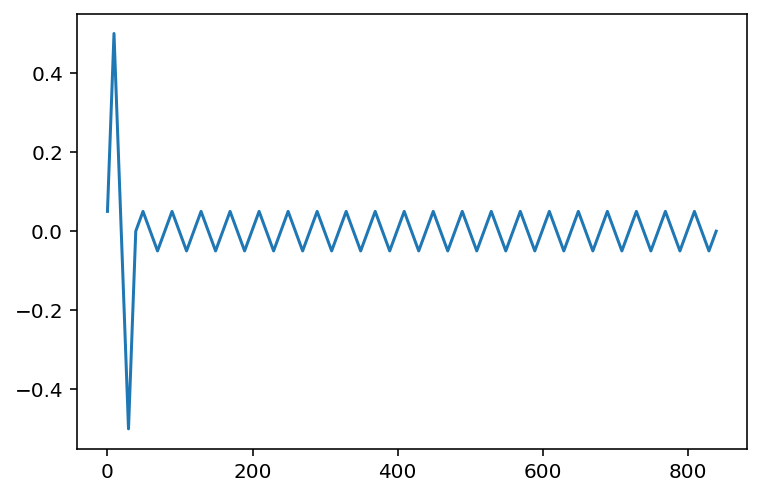

In [9]:
plt.plot(dataset_htl["xy"])

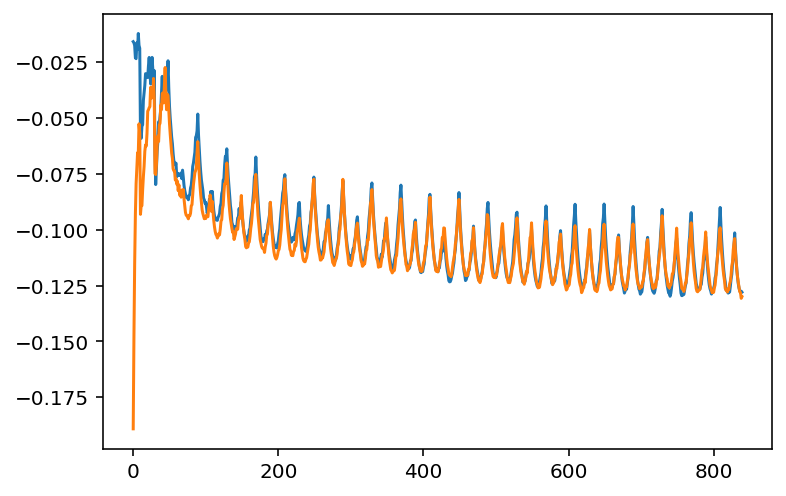

In [10]:
plt.plot(dataset_htl["soft"].map_elements(function=lambda x: np.mean(x.to_numpy())))
plt.plot(dataset_gq["soft"].map_elements(function=lambda x: np.mean(x.to_numpy())))
# plt.plot(dataset2["soft"].map_elements(function=lambda x: np.mean(x.to_numpy())))

(-0.1, 0.1)

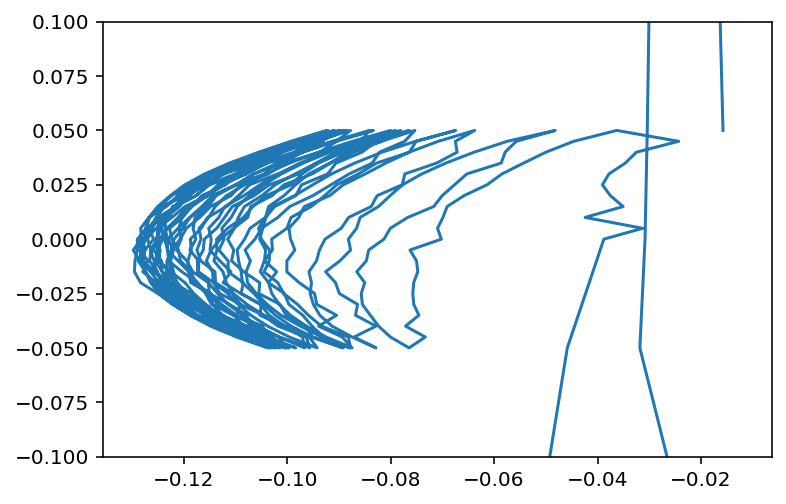

In [11]:
plt.plot(dataset_htl["soft"].map_elements(function=lambda x: np.mean(x.to_numpy())), dataset_htl["xy"])
plt.ylim(-.1, .1)

In [12]:
dataset.head()

frame,xy,id,soft,sigma_xx,sigma_yy,sigma_xy,sigma_dev
i64,f32,list[u32],list[f32],list[f32],list[f32],list[f32],list[f32]
0,0.05,"[0, 1, … 1]","[0.162237, -0.814894, … 0.102892]","[0.873191, -2.423546, … 1.27818]","[0.276614, -3.299168, … 7.097918]","[0.067729, 1.515845, … -0.607095]","[0.600409, 1.750571, … 5.851317]"
1,0.1,"[0, 1, … 1]","[0.523056, 0.378923, … -0.346304]","[-0.20114, 0.061728, … 1.694166]","[-0.037184, 0.759857, … 7.286613]","[0.474919, 0.180188, … -0.584632]","[0.502424, 0.721007, … 5.622922]"
2,0.15,"[0, 1, … 1]","[0.27603, 0.680039, … -0.444217]","[-2.323806, 2.105456, … 1.604105]","[-2.177722, 1.062931, … 3.426161]","[1.421274, 0.732644, … -0.726971]","[1.428762, 1.274216, … 1.961727]"
3,0.2,"[0, 1, … 1]","[-0.086832, -0.386071, … -0.475322]","[-2.679916, -3.904081, … 2.008591]","[-2.385756, -3.440543, … 3.40277]","[-1.300793, -0.563031, … -0.731366]","[1.333639, 0.729295, … 1.574367]"
4,0.25,"[0, 1, … 1]","[0.248765, 0.797602, … -0.023523]","[1.225608, 0.888439, … 1.912741]","[-2.164606, 2.193549, … 4.936426]","[-0.262163, -0.752436, … -0.632571]","[3.400335, 1.506477, … 3.089145]"


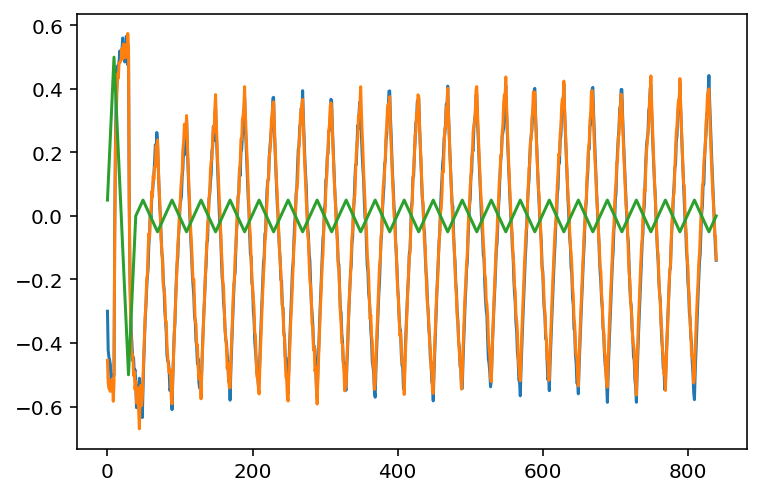

In [13]:
plt.plot(dataset_htl["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy())))
plt.plot(dataset_gq["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy())))
plt.plot(dataset_htl["xy"])

(-0.1, 0.1)

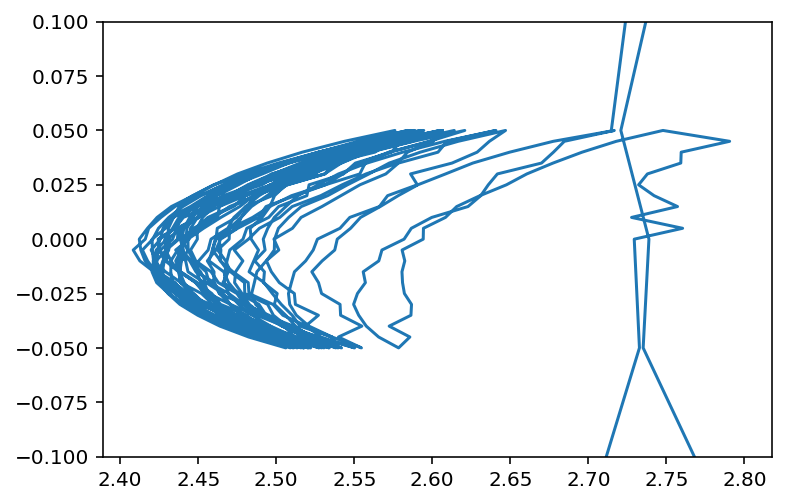

In [14]:
plt.plot(dataset_htl["sigma_dev"].map_elements(function=lambda x: np.mean(x.to_numpy())), dataset_htl["xy"])
plt.ylim(-.1, .1)

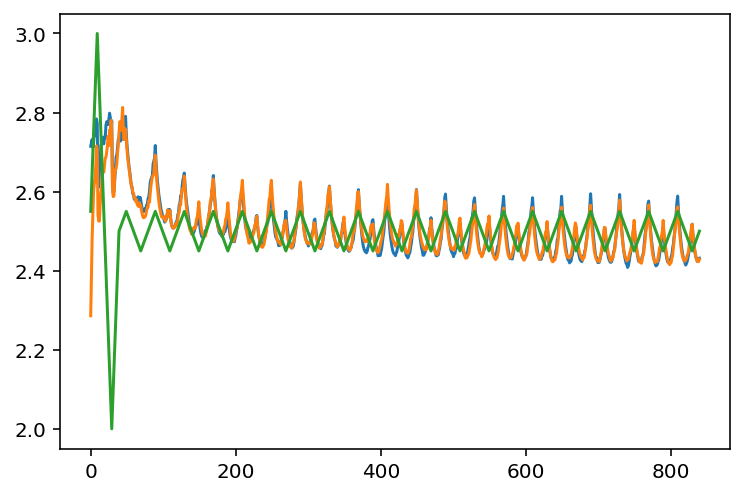

In [15]:
plt.plot(dataset_htl["sigma_dev"].map_elements(function=lambda x: np.mean(x.to_numpy())))
plt.plot(dataset_gq["sigma_dev"].map_elements(function=lambda x: np.mean(x.to_numpy())))
plt.plot(dataset_htl["xy"] + 2.5)

In [16]:
dataset_htl.head()

frame,xy,id,soft,sigma_xx,sigma_yy,sigma_xy,sigma_dev
i64,f32,list[u32],list[f32],list[f32],list[f32],list[f32],list[f32]
0,0.05,"[1, 0, … 0]","[-0.64857, 0.257182, … 0.507783]","[-3.457904, -0.865785, … -1.069471]","[-2.342877, -0.772137, … -0.872499]","[1.340869, -1.502285, … -2.221401]","[1.743908, 1.505201, … 2.230117]"
1,0.1,"[1, 0, … 0]","[-0.823665, 0.151798, … 0.503793]","[-2.554441, -0.144518, … 2.336242]","[-3.494063, 0.387693, … 2.271555]","[1.366274, -0.170932, … -2.570159]","[1.65819, 0.558987, … 2.570973]"
2,0.15,"[1, 0, … 0]","[0.267856, 0.792825, … 0.793413]","[4.630625, -1.139976, … -0.396299]","[1.159554, -0.653378, … -0.585363]","[-1.376314, 0.226286, … -1.973718]","[3.733976, 0.53664, … 1.982753]"
3,0.2,"[1, 0, … 0]","[-0.23922, 1.55545, … 0.042015]","[-3.691144, 2.832414, … 1.098956]","[-2.060148, -2.458293, … -0.328085]","[0.630537, 2.521576, … -3.077953]","[1.748635, 5.860881, … 3.392674]"
4,0.25,"[1, 0, … 0]","[-0.513485, 1.473639, … 0.134189]","[-2.847697, 3.705405, … 2.04882]","[-1.926425, -2.187237, … -1.067822]","[1.343321, 2.547759, … -3.080297]","[1.628881, 6.419837, … 4.381972]"


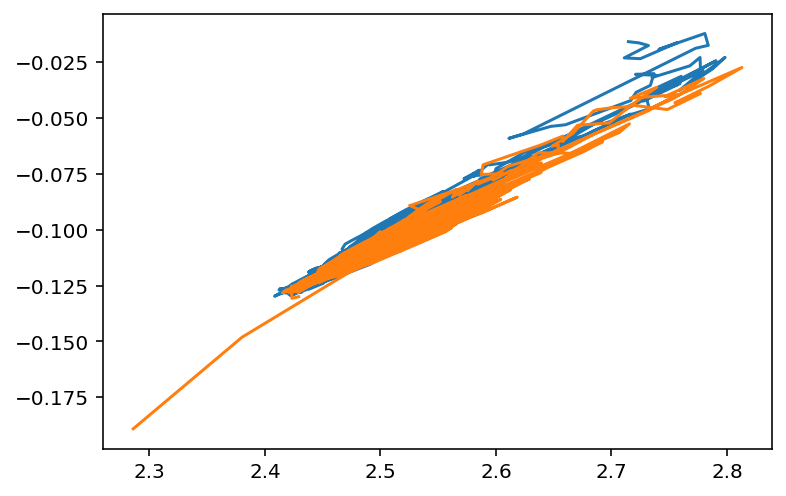

In [17]:
plt.plot(dataset_htl[:]["sigma_dev"].map_elements(function=lambda x: np.mean(x.to_numpy())), dataset_htl[:]["soft"].map_elements(function=lambda x: np.mean(x.to_numpy())))
plt.plot(dataset_gq[:]["sigma_dev"].map_elements(function=lambda x: np.mean(x.to_numpy())), dataset_gq[:]["soft"].map_elements(function=lambda x: np.mean(x.to_numpy())))
# plt.ylim(-.1, .1)

In [55]:
query = freud.locality.AABBQuery.from_system(traj_htl[-201])
nlist = query.query(traj_htl[-201].particles.position, {"r_max": 1.5}).toNeighborList()


In [56]:
nlist.segments

array([     0,      9,     16, ..., 263282, 263289, 263296], dtype=uint32)

In [57]:
idx = 30
ids = nlist.point_indices[nlist.segments[idx]:nlist.segments[idx] + nlist.neighbor_counts[idx]]
ids, ids.shape

(array([   30, 31885, 31889, 32063, 32069, 32243, 32251, 32439, 32612],
       dtype=uint32),
 (9,))

array([0.        , 0.10016742, 0.20135792, 0.30469265, 0.41151685,
       0.52359878, 0.64350111, 0.7753975 , 0.92729522, 1.11976951,
       1.57079633, 2.02182314, 2.21429744, 2.36619516, 2.49809154,
       2.61799388, 2.73007581, 2.8369    , 2.94023473, 3.04142523,
       3.14159265, 3.24176007, 3.34295057, 3.44628531, 3.5531095 ,
       3.66519143, 3.78509376, 3.91699015, 4.06888787, 4.26136217,
       4.71238898, 5.16341579, 5.35589009, 5.50778781, 5.6396842 ,
       5.75958653, 5.87166846, 5.97849265, 6.08182739, 6.18301789])

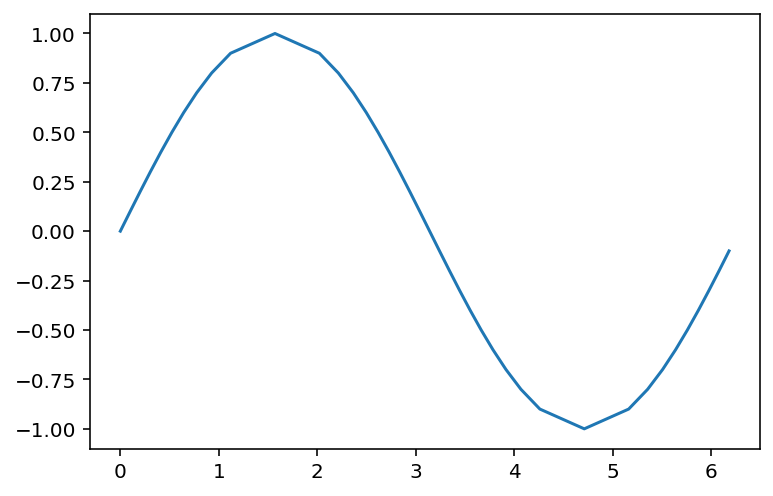

In [58]:
y1 = np.concatenate([
    np.arcsin(np.linspace(0, 1, 11)),
    np.arcsin(np.linspace(-1, 1, 21))[1:] + np.pi,
    np.arcsin(np.linspace(-1, 0, 11))[1:-1] + 2*np.pi,
])
x1 = np.linspace(0, 2 * np.pi, y1.shape[0])

xy = np.concatenate([
    np.linspace(0, 1, 11),
    np.linspace(1, -1, 21)[1:],
    np.linspace(-1, 0, 11)[1:-1],
])
plt.plot(y1, xy)
y1

In [59]:
xy

array([ 0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,
        0.9,  0.8,  0.7,  0.6,  0.5,  0.4,  0.3,  0.2,  0.1,  0. , -0.1,
       -0.2, -0.3, -0.4, -0.5, -0.6, -0.7, -0.8, -0.9, -1. , -0.9, -0.8,
       -0.7, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1])

In [60]:
np.arccos(-1), np.arcsin(12)

/tmp/ipykernel_477911/1336137259.py:1: RuntimeWarning: invalid value encountered in arcsin
  np.arccos(-1), np.arcsin(12)


(3.141592653589793, nan)

In [61]:
len(y1)

40

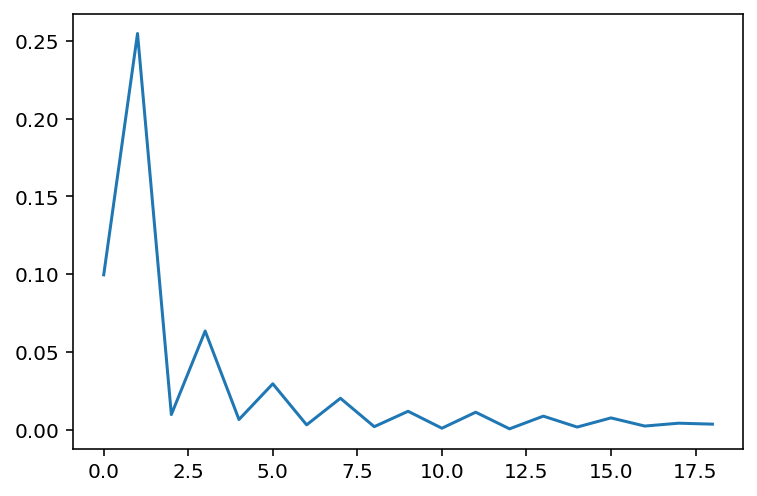

In [62]:
var = np.vstack(dataset_htl[-201:-1]["soft"].to_numpy())
var = var.reshape(5, -1, var.shape[1]).mean(axis=0)
# take fft of var
var_fft = np.fft.fft(var, axis=0)
# plt.hist(var, bins=100)
plt.plot(np.abs(var_fft.mean(axis=1))[1:20])

In [63]:
var.shape

(40, 32768)

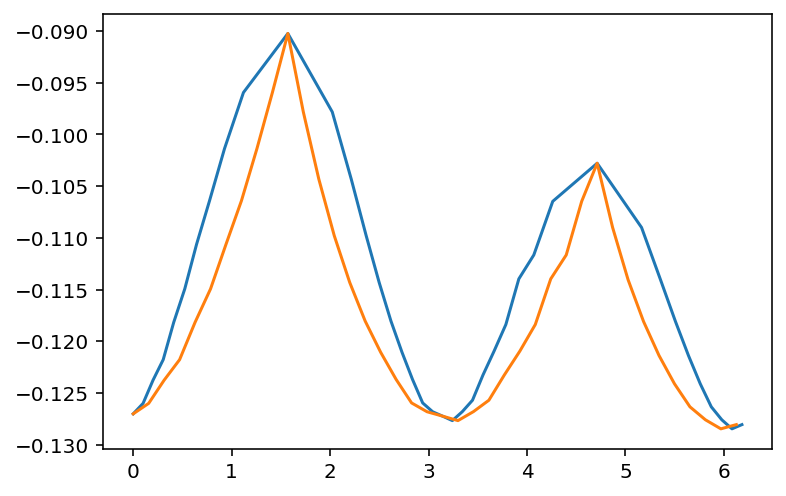

In [64]:
y2 = np.linspace(0, 2 * np.pi, var.shape[0], endpoint=False)
plt.plot(y1, var[:, :].mean(axis=1))
plt.plot(y2, var[:, :].mean(axis=1))

In [65]:
tmp = var_fft[:, ids].mean(axis=1)

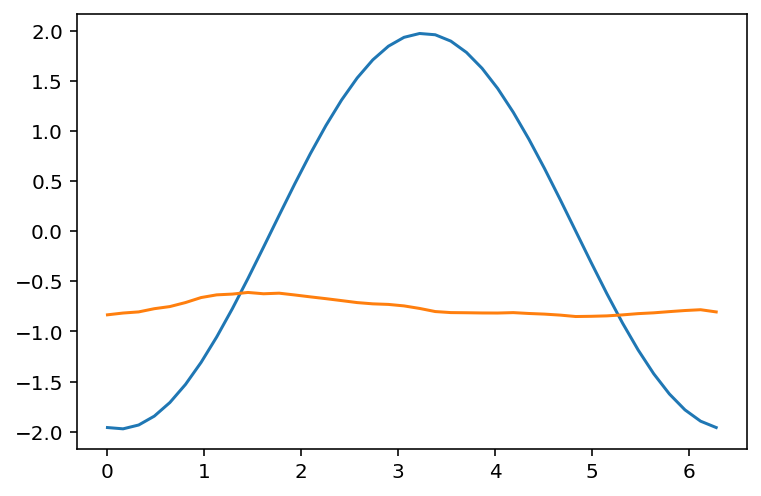

In [66]:
x = np.linspace(0, 1, len(tmp))*2*np.pi
phase = np.angle(tmp)
mag = np.abs(tmp)
y = mag[1]*np.sin(x + phase[1]) 
plt.plot(x, y)
plt.plot(x, var[:, ids].mean(axis=1))

In [67]:
# get freqs
freqs = np.fft.fftfreq(var.shape[0], d=1)
freqs[1:20]

array([0.025, 0.05 , 0.075, 0.1  , 0.125, 0.15 , 0.175, 0.2  , 0.225,
       0.25 , 0.275, 0.3  , 0.325, 0.35 , 0.375, 0.4  , 0.425, 0.45 ,
       0.475])

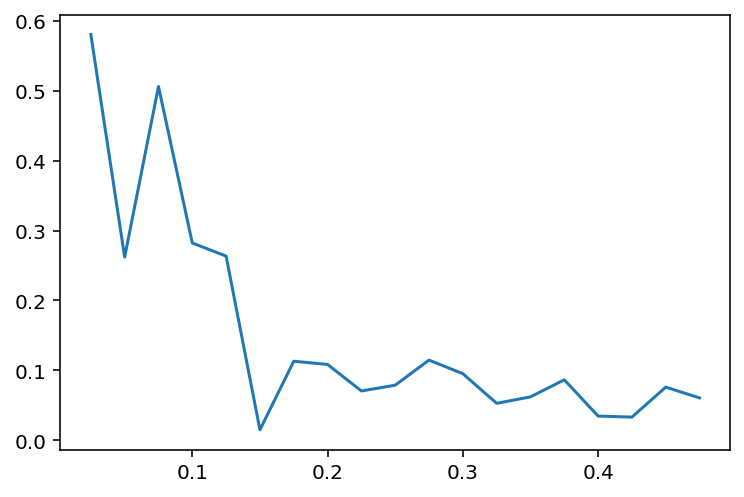

In [68]:
idx = 100
ids = nlist.point_indices[nlist.segments[idx]:nlist.segments[idx] + nlist.neighbor_counts[idx]]

plt.plot(freqs[1:20], np.abs(var_fft[:, ids].mean(axis=1))[1:20])

In [69]:
import scipy.optimize

In [80]:
def _fit(x, a, b, c):
    return a * np.sin(x + b) + c

ratios = []
angles = []
weights = []
for idx in tqdm(range(1000)):
    ids = nlist.point_indices[nlist.segments[idx]:nlist.segments[idx] + nlist.neighbor_counts[idx]]

    fft = np.abs(var_fft[1:20, ids].mean(axis=1))
    ratios.append(fft[1])
    sigma_xy = -dataset_htl[-201:-1]["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])).to_numpy().reshape(5, -1).mean(axis=0)
    # plt.plot(y1, sigma_xy)
    x = np.linspace(0, 2 * np.pi, 40, endpoint=True)
    # plt.plot(x, 0.5*np.sin(x))

    popt, pcov = scipy.optimize.curve_fit(_fit, y1, sigma_xy, p0=[0.5, 0, 0])
    angles.append(fft[0])

    # weights.append(np.sqrt(np.sum(fft**2)))
# plt.hist(ratios, weights=weights, bins=100, density=True, alpha=0.5)
# plt.hist(ratios, bins=100, density=True, alpha=0.5)
# plt.yscale('log')

100%|██████████| 1000/1000 [00:06<00:00, 165.68it/s]


(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 1.],
        [0., 0., 0., ..., 1., 1., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-6.43963074, -6.23335622, -6.0270817 , -5.82080719, -5.61453267,
        -5.40825815, -5.20198364, -4.99570912, -4.7894346 , -4.58316009,
        -4.37688557, -4.17061105, -3.96433653, -3.75806202, -3.5517875 ,
        -3.34551298, -3.13923847, -2.93296395, -2.72668943, -2.52041492,
        -2.3141404 , -2.10786588, -1.90159137, -1.69531685, -1.48904233,
        -1.28276781, -1.0764933 , -0.87021878, -0.66394426, -0.45766975,
        -0.25139523, -0.04512071,  0.1611538 ,  0.36742832,  0.57370284,
         0.77997736,  0.98625187,  1.19252639,  1.39880091,  1.60507542,
         1.81134994]),
 array([-3.46631948, -3.31171846, -3.15711744, -3.00251642, -2.8479154 ,
        -2.69331438, -2.53871336, -2.38411234, -2.22951132, -2.0749103 

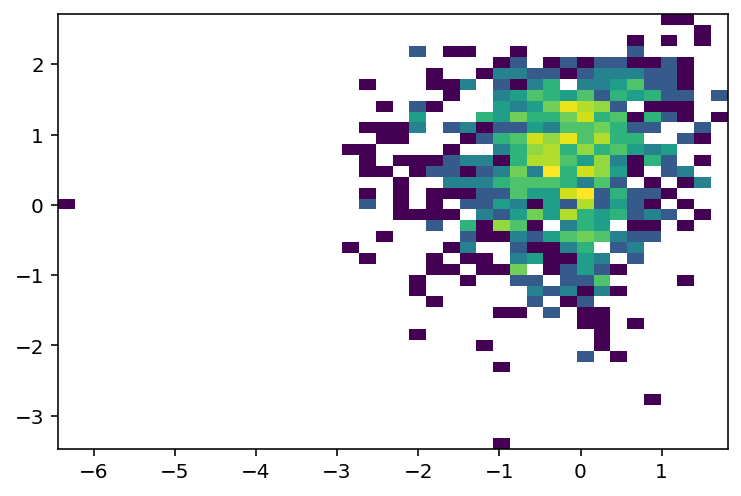

In [81]:
plt.hist2d(np.log(ratios), np.log(angles), bins=40, norm=mpl.colors.LogNorm())

In [82]:
scipy.stats.spearmanr(np.log(ratios), np.arctan(angles))

SpearmanrResult(correlation=0.12073082473082476, pvalue=0.0001296747125911806)

/home/ian/.local/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


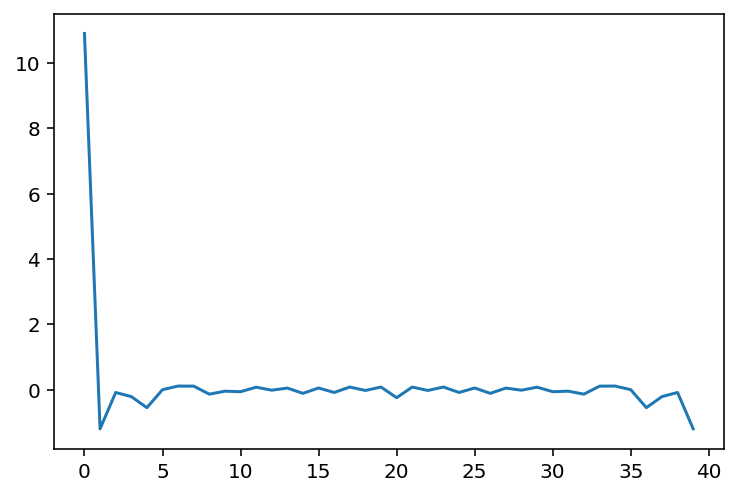

In [54]:
plt.plot(var_fft[:, 1])

ValueError: 'c' argument has 1310720 elements, which is inconsistent with 'x' and 'y' with size 32768.

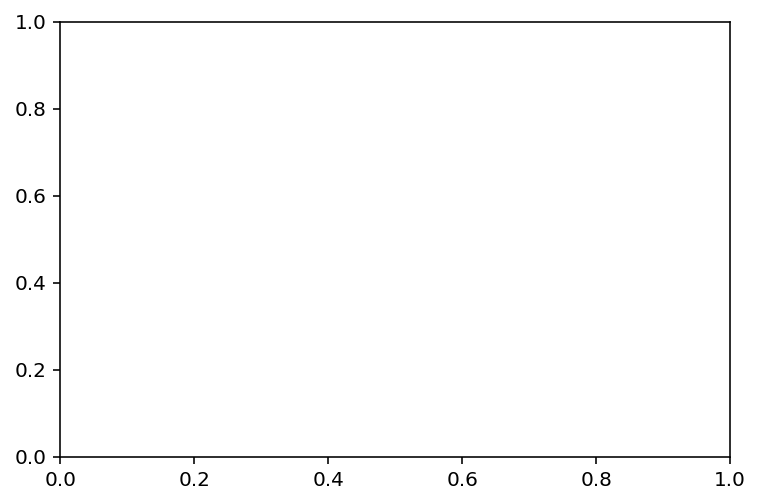

In [45]:
pos = traj_htl[-201].particles.position
plt.scatter(pos[:, 0], pos[:, 1], c=var, cmap="viridis", s=1)

ValueError: 'c' argument has 1310720 elements, which is inconsistent with 'x' and 'y' with size 32768.

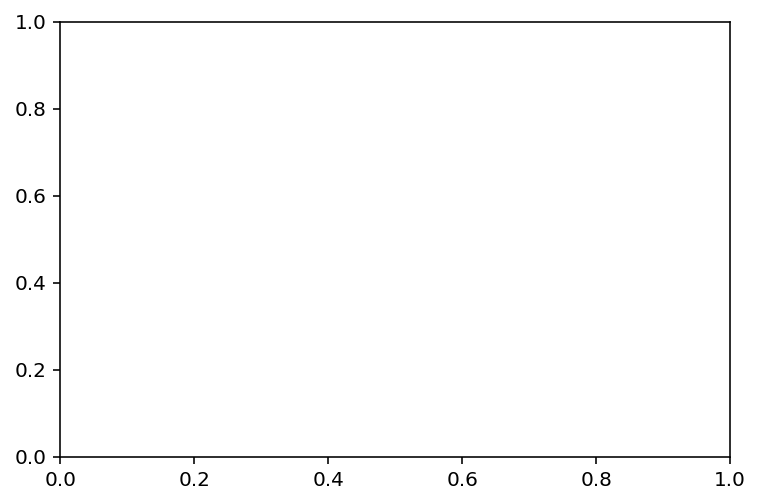

In [ ]:
pos = traj_htl[-201].particles.position
plt.scatter(pos[:, 0], pos[:, 1], c=var, cmap="viridis", s=1)

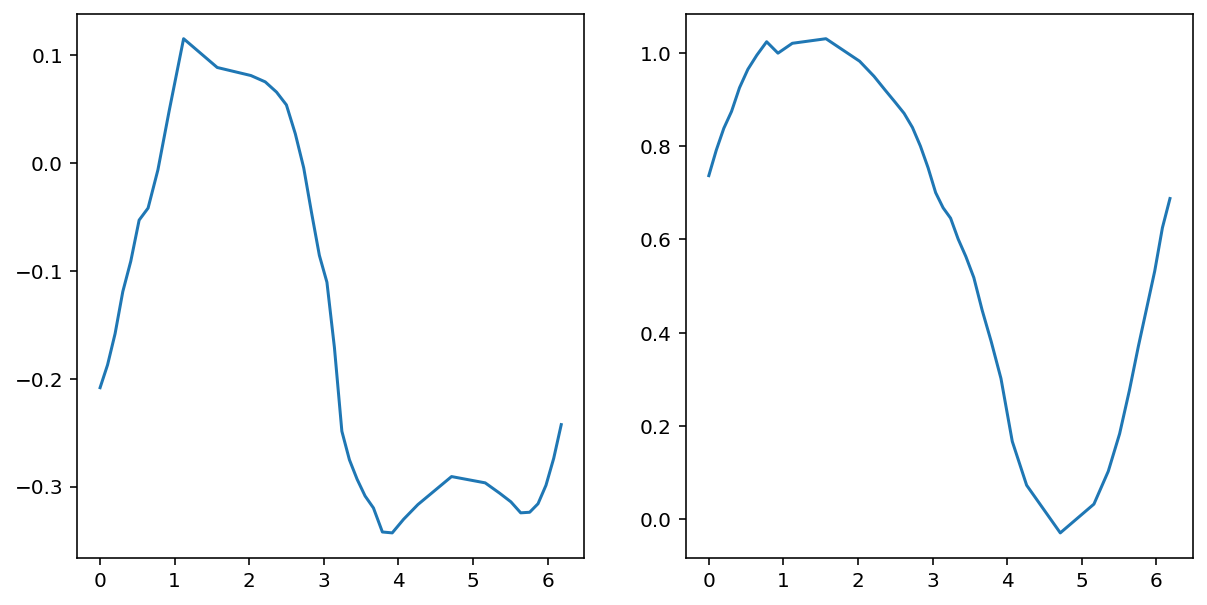

In [100]:
idx = 12
ids = nlist.point_indices[nlist.segments[idx]:nlist.segments[idx] + nlist.neighbor_counts[idx]]

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
plt.sca(axs[0])
plt.plot(y1, dataset_htl[-201:-1]["soft"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])).to_numpy().reshape(5, -1).mean(axis=0))
# plt.plot(dataset_gq["soft"].map_elements(function=lambda x: x[3]))
# plt.plot(dataset2["soft"].map_elements(function=lambda x:
# np.mean(x.to_numpy())))
plt.sca(axs[1])
plt.plot(y1, -dataset_htl[-201:-1]["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])).to_numpy().reshape(5, -1).mean(axis=0))

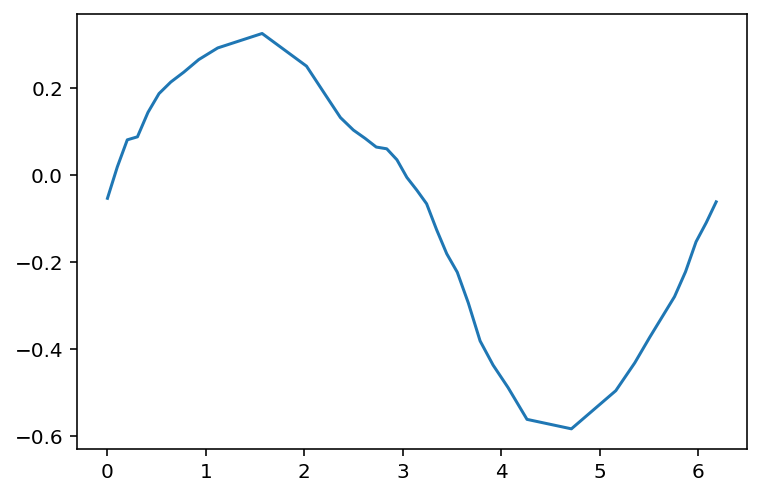

In [66]:
import scipy.optimize

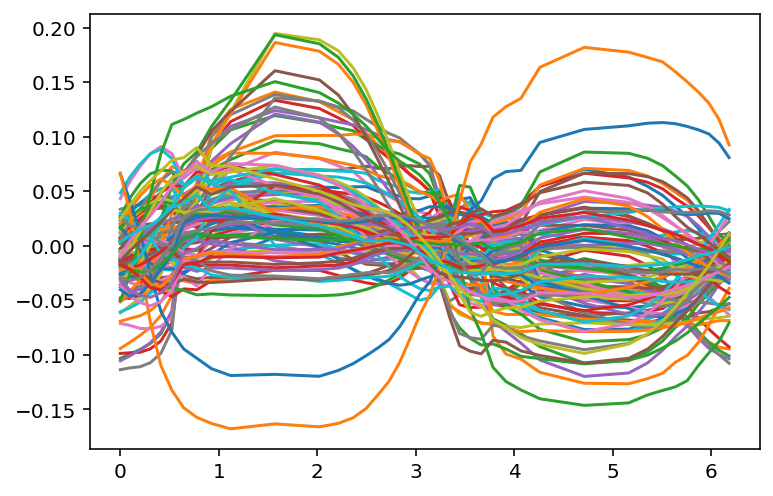

In [67]:
for seg, nn in list(zip(nlist.segments, nlist.neighbor_counts))[:100]:
    ids2 = nlist.point_indices[seg:seg + nn]
    soft = dataset_htl[-401:-1]["soft"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids2])).to_numpy().reshape(10, -1).mean(axis=0)
    plt.plot(y1, soft - soft.mean())

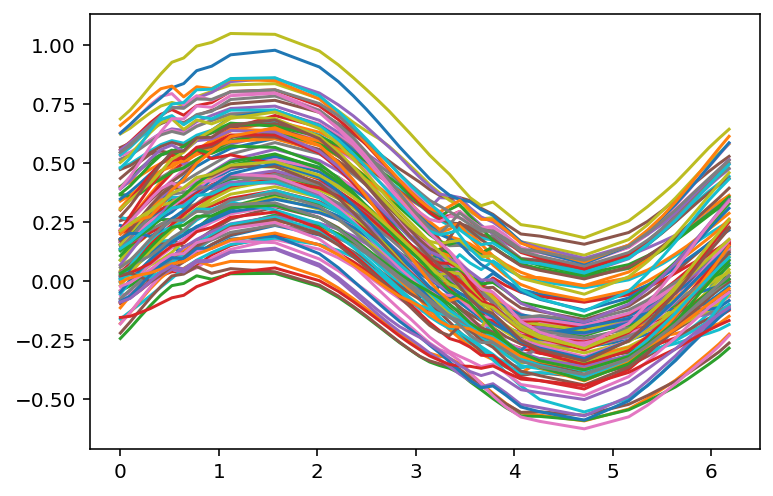

In [40]:
def _fit(x, a, b, c):
    return a * np.sin(x + b) + c

bs = []

for seg, nn in list(zip(nlist.segments, nlist.neighbor_counts))[:100]:
    ids2 = nlist.point_indices[seg:seg + nn]
    sigma_xy = -dataset_htl[-401:-1]["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids2])).to_numpy().reshape(10, -1).mean(axis=0)
    plt.plot(y1, sigma_xy)
    x = np.linspace(0, 2 * np.pi, 40, endpoint=True)
    # plt.plot(x, 0.5*np.sin(x))

    popt, pcov = scipy.optimize.curve_fit(_fit, y1, sigma_xy, p0=[0.5, 0, 0])
    bs.append(popt[1])


# plt.plot(x, _fit(x, *popt))

In [41]:
bs

[0.004693686232508409,
 0.020306679671226607,
 0.04017947847735889,
 0.001891765081696837,
 0.08233469958555702,
 0.06965566955595463,
 0.017156021452886725,
 0.039620867050241794,
 -0.016582874752722514,
 0.03962358726136151,
 0.08678825684883142,
 0.06992099266148072,
 0.009912266695472965,
 0.020160003224935535,
 0.08017917308433688,
 0.11586820061335665,
 0.10753137769795569,
 0.1887505576939088,
 0.14034421032650485,
 0.2832238663993077,
 0.16948246285367527,
 0.10009314854733646,
 0.17714800838093397,
 0.238441041527671,
 0.23710957020761858,
 0.23392403690802135,
 0.26661227536402055,
 0.2586119341508081,
 0.24645279090747085,
 0.2544198696835076,
 0.026230638626491463,
 0.2254819779329969,
 0.1498848443209204,
 0.17117481175226132,
 0.12797984334863707,
 0.24432831077221906,
 0.046923461134262406,
 0.08517206250551866,
 0.054358684149552555,
 0.008286120604404746,
 0.06991353659924104,
 0.06930603762158874,
 0.06096518715091567,
 0.021818861383401833,
 0.04093392587549159,
 0.0

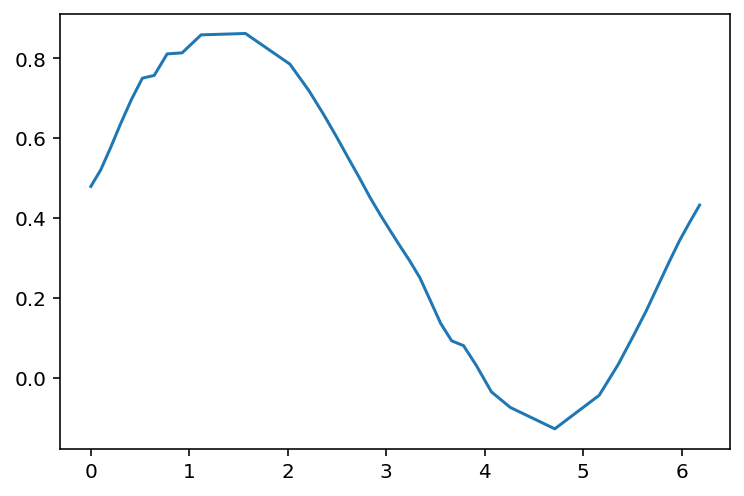

In [42]:
plt.plot(y1, sigma_xy)

(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  4., 12., 12.,
        10.,  9., 12., 11.,  5., 11.,  6.,  2.,  2.,  3.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]),
 array([-1.57079633, -1.53906307, -1.50732981, -1.47559655, -1.44386329,
        -1.41213003, -1.38039677, -1.34866351, -1.31693025, -1.28519699,
        -1.25346374, -1.22173048, -1.18999722, -1.15826396, -1.1265307 ,
        -1.09479744, -1.06306418, -1.03133092, -0.99959766, -0.9678644 ,
        -0.93613114, -0.90439789, -0.87266463, -0.84093137, -0.80919811,
        -0.77746485, -0.74573159, -0.71399833, -0.68226507, -0.65053181,
 

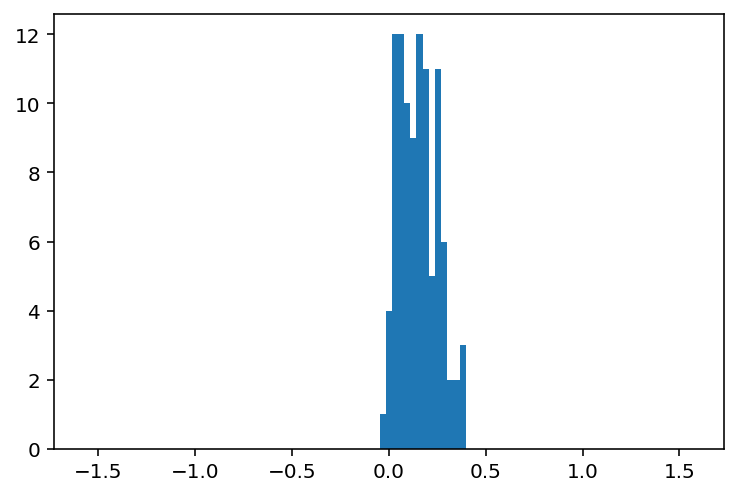

In [43]:
plt.hist(bs, bins=np.linspace(-np.pi/2, np.pi/2, 100))

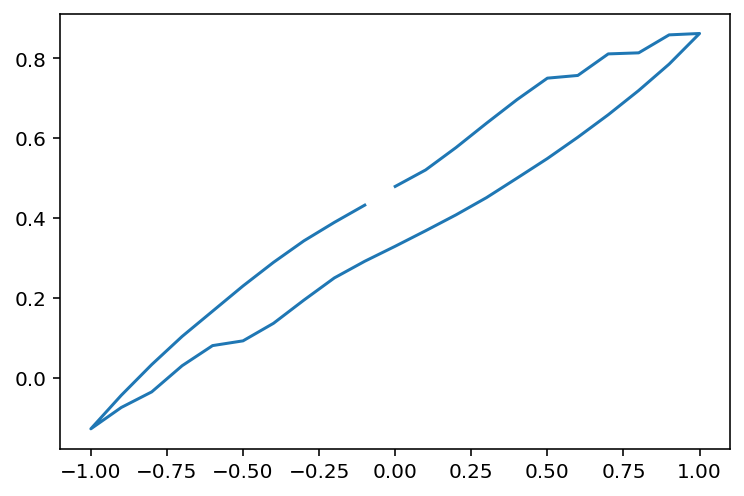

In [44]:
plt.plot(xy, sigma_xy)

(array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  4., 12., 12.,
        10.,  9., 12., 11.,  7.,  9.,  7.,  1.,  4.,  1.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.]),
 array([-1.57079633, -1.53906307, -1.50732981, -1.47559655, -1.44386329,
        -1.41213003, -1.38039677, -1.34866351, -1.31693025, -1.28519699,
        -1.25346374, -1.22173048, -1.18999722, -1.15826396, -1.1265307 ,
        -1.09479744, -1.06306418, -1.03133092, -0.99959766, -0.9678644 ,
        -0.93613114, -0.90439789, -0.87266463, -0.84093137, -0.80919811,
        -0.77746485, -0.74573159, -0.71399833, -0.68226507, -0.65053181,
 

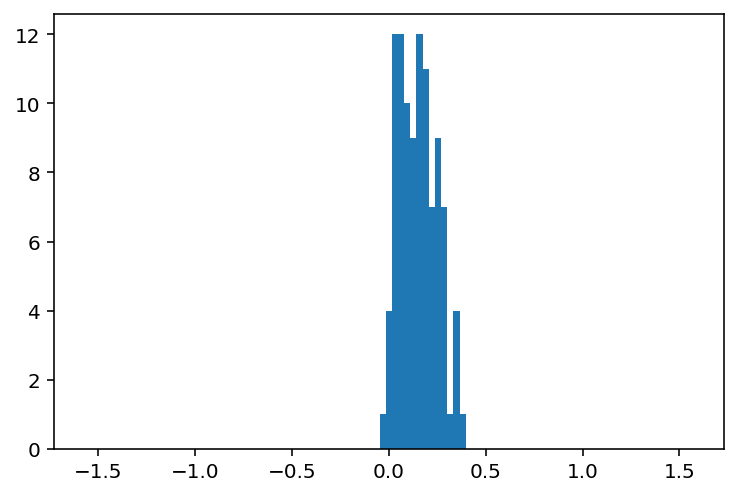

In [52]:
plt.hist(bs, bins=np.linspace(-np.pi/2, np.pi/2, 100))

In [46]:
popt

array([0.48856966, 0.16791565, 0.39807919])

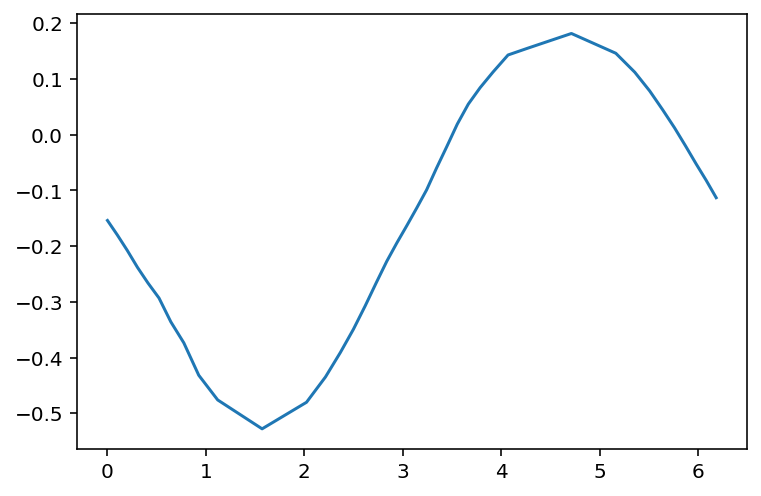

In [47]:
plt.plot(y1, dataset_htl[-401:-1]["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])).to_numpy().reshape(10, -1).mean(axis=0))

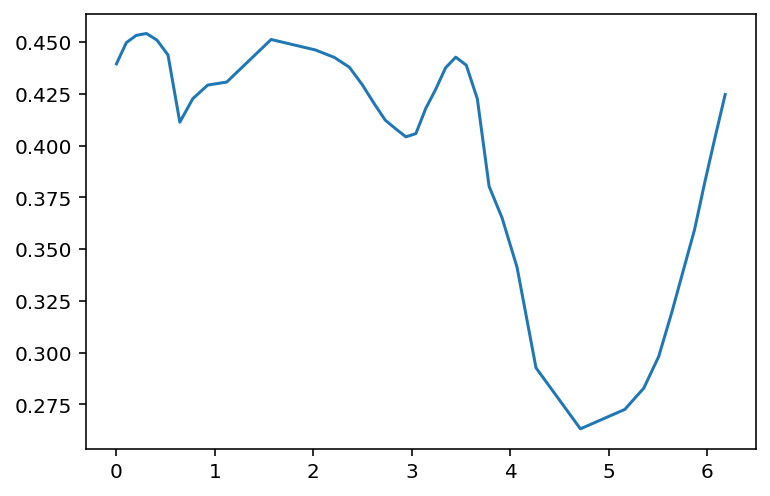

In [48]:
dataset = dataset_htl
sigma_xx = np.vstack(dataset["sigma_xx"].to_numpy())
sigma_yy = np.vstack(dataset["sigma_yy"].to_numpy())
sigma_xy = np.vstack(dataset["sigma_xy"].to_numpy())
sigma_xx = np.mean(sigma_xx[:, ids], axis=1)
sigma_yy = np.mean(sigma_yy[:, ids], axis=1)
sigma_xy = np.mean(sigma_xy[:, ids], axis=1)
# sigma_dev = np.sqrt((sigma_xx - sigma_yy)**2 + sigma_xy**2)
sigma_dev = sigma_yy - sigma_xx

plt.plot(y1, sigma_dev[-201:-1].reshape(5, -1).mean(axis=0))

In [49]:
dataset_htl[38+100:].head()

frame,xy,id,soft,sigma_xx,sigma_yy,sigma_xy,sigma_dev
i64,f32,list[u32],list[f32],list[f32],list[f32],list[f32],list[f32]
138,0.003,"[1, 0, … 0]","[-1.431922, -0.43756, … 0.076687]","[2.330278, 0.052174, … -0.455125]","[0.421602, -1.882498, … -1.064084]","[0.937215, -0.446331, … -2.21152]","[2.126362, 1.985489, … 2.293829]"
139,0.0,"[1, 0, … 0]","[-1.44377, -0.424218, … 0.088577]","[2.376965, 0.070769, … -0.499596]","[0.298777, -1.860344, … -1.131596]","[0.959031, -0.402453, … -2.212405]","[2.2888, 1.972604, … 2.300904]"
140,-0.003,"[1, 0, … 0]","[-1.452715, -0.411991, … 0.102932]","[2.410223, 0.088937, … -0.550831]","[0.248921, -1.845335, … -1.208002]","[0.998195, -0.361338, … -2.209755]","[2.380676, 1.967733, … 2.305405]"
141,-0.006,"[1, 0, … 0]","[-1.439072, -0.398859, … 0.188725]","[2.363561, 0.182734, … -0.473559]","[0.157697, -1.893604, … -1.3124]","[1.075495, -0.306465, … -2.259756]","[2.454084, 2.098833, … 2.410426]"
142,-0.009,"[1, 0, … 0]","[-1.444466, -0.3939, … 0.189374]","[2.458984, 0.18886, … -0.510613]","[0.106288, -1.844088, … -1.374851]","[1.114097, -0.290121, … -2.22252]","[2.60315, 2.053545, … 2.384639]"


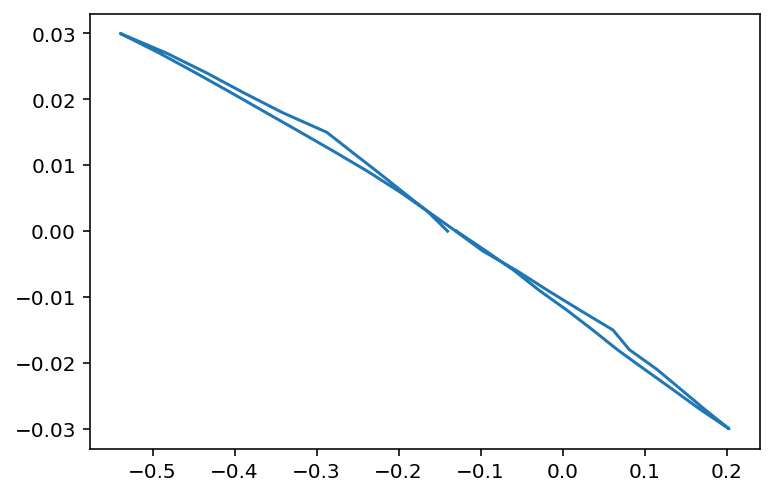

In [50]:
plt.plot(dataset_htl[-41:]["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])), dataset_htl[-41:]["xy"])

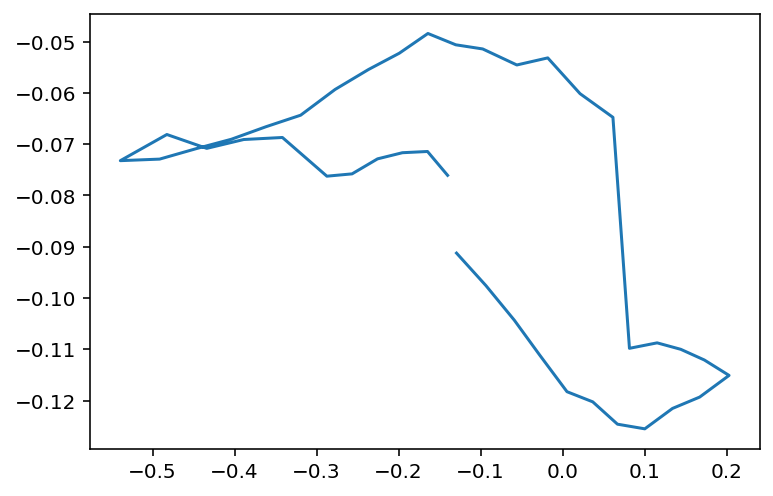

In [51]:
plt.plot(dataset_htl[-41:]["sigma_xy"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])), dataset_htl[-41:]["soft"].map_elements(function=lambda x: np.mean(x.to_numpy()[ids])))

In [ ]:
exper

'/media/ian/Data2/monk/2d-osc-shear/workspace/634e14bc75836df75158fb15f379d8bb/aqs_experiments_longer/max-shear-0.01/temp-0.0000/traj_period-0.001_more-fire.gsd'